In [23]:
%load_ext autoreload 
# il s’applique à tous les 
#fichiers .py que le notebook a importés et sa permet 
# de verifier si tous marche 
%autoreload 2
import sys; sys.path.append("..")
#Permet au notebook, qui est dans notebooks, 
#de trouver le dossier src situé au-dessus
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [24]:
import yfinance as yf
test = yf.download("TTE.PA", start="2024-01-01", end="2024-02-01", auto_adjust=True)

[*********************100%***********************]  1 of 1 completed


In [25]:
test

Price,Close,High,Low,Open,Volume
Ticker,TTE.PA,TTE.PA,TTE.PA,TTE.PA,TTE.PA
Date,,,,,
2024-01-02,53.505135,53.781334,53.203039,53.384294,4444831
2024-01-03,53.289356,53.574186,52.883686,53.436086,3492054
2024-01-04,53.928055,54.376880,53.556911,53.669118,3956219
2024-01-05,53.945328,54.117953,53.444714,53.703654,2376845
2024-01-08,52.262230,53.556918,52.262230,53.513762,3900649
2024-01-09,51.891090,52.797371,51.891090,52.521171,3053098
2024-01-10,51.588989,52.046445,51.528571,51.787508,2757095
2024-01-11,51.338688,51.942876,51.235114,51.537206,4264632


In [26]:
y=test["Close"]
print(y.head())

Ticker         TTE.PA
Date                 
2024-01-02  53.505135
2024-01-03  53.289356
2024-01-04  53.928055
2024-01-05  53.945328
2024-01-08  52.262230


In [27]:
import yfinance as yf
tickers = ["TTE.PA", "BNP.PA", "MC.PA", "AIR.PA", "SAN.PA"]
tes=yf.download(tickers ,start ="2005-01-01", end= "2025-12-31", auto_adjust= True )
y=tes["Close"]
print(y.head())

[*********************100%***********************]  5 of 5 completed

Ticker         AIR.PA     BNP.PA      MC.PA     SAN.PA     TTE.PA
Date                                                             
2005-01-03  15.835875  17.847837  36.960773  24.980856  11.679478
2005-01-04  15.542071  17.980785  36.764866  24.896610  11.635840
2005-01-05  15.409861  17.881075  36.209805  24.538536  11.526755
2005-01-06  15.865252  18.146965  36.340408  24.285778  11.614026
2005-01-07  16.100294  18.346384  36.601620  24.370033  11.650387


In [28]:
r=y.isna().sum()
t=len(y)
print(t)
print(r)

5375
Ticker
AIR.PA    0
BNP.PA    0
MC.PA     0
SAN.PA    0
TTE.PA    0
dtype: int64


In [29]:
y.to_csv("../data/prices.csv")

In [30]:
prices=pd.read_csv("../data/prices.csv",index_col=0, parse_dates=True)

In [31]:
print(prices.head())

               AIR.PA     BNP.PA      MC.PA     SAN.PA     TTE.PA
Date                                                             
2005-01-03  15.835875  17.847837  36.960773  24.980856  11.679478
2005-01-04  15.542071  17.980785  36.764866  24.896610  11.635840
2005-01-05  15.409861  17.881075  36.209805  24.538536  11.526755
2005-01-06  15.865252  18.146965  36.340408  24.285778  11.614026
2005-01-07  16.100294  18.346384  36.601620  24.370033  11.650387


In [32]:
from src.data import load_prices

tickers = ["TTE.PA", "BNP.PA", "MC.PA", "AIR.PA", "SAN.PA"]
prices = load_prices(tickers, "2005-01-01", "2025-12-31", "../data/prices.csv")
prices.head()

,AIR.PA,BNP.PA,MC.PA,SAN.PA,TTE.PA
Date,,,,,
2005-01-03,15.835875,17.847837,36.960773,24.980856,11.679478
2005-01-04,15.542071,17.980785,36.764866,24.896610,11.635840
2005-01-05,15.409861,17.881075,36.209805,24.538536,11.526755
2005-01-06,15.865252,18.146965,36.340408,24.285778,11.614026
2005-01-07,16.100294,18.346384,36.601620,24.370033,11.650387


In [33]:
test = load_prices(tickers, "2024-01-01", "2024-02-01", "../data/test.csv")
test.head()

[*********************100%***********************]  5 of 5 completed


Ticker,AIR.PA,BNP.PA,MC.PA,SAN.PA,TTE.PA
Date,,,,,
2024-01-02,133.345276,50.696484,681.810913,79.159782,53.505135
2024-01-03,129.456665,49.344257,655.783203,80.109108,53.289356
2024-01-04,131.551971,50.336426,658.046509,80.849403,53.928055
2024-01-05,131.853989,50.408436,649.653687,81.415520,53.945328
2024-01-08,135.157425,50.520454,651.916748,81.981621,52.262230


In [34]:
prices.head()

,AIR.PA,BNP.PA,MC.PA,SAN.PA,TTE.PA
Date,,,,,
2005-01-03,15.835875,17.847837,36.960773,24.980856,11.679478
2005-01-04,15.542071,17.980785,36.764866,24.896610,11.635840
2005-01-05,15.409861,17.881075,36.209805,24.538536,11.526755
2005-01-06,15.865252,18.146965,36.340408,24.285778,11.614026
2005-01-07,16.100294,18.346384,36.601620,24.370033,11.650387


In [35]:
prices.shift(1).head()

,AIR.PA,BNP.PA,MC.PA,SAN.PA,TTE.PA
Date,,,,,
2005-01-03,NaN,NaN,NaN,NaN,NaN
2005-01-04,15.835875,17.847837,36.960773,24.980856,11.679478
2005-01-05,15.542071,17.980785,36.764866,24.896610,11.635840
2005-01-06,15.409861,17.881075,36.209805,24.538536,11.526755
2005-01-07,15.865252,18.146965,36.340408,24.285778,11.614026


In [36]:
t= prices
t1= prices.shift(1)
returns=np.log(t/t1)
print(returns.head())

              AIR.PA    BNP.PA     MC.PA    SAN.PA    TTE.PA
Date                                                        
2005-01-03       NaN       NaN       NaN       NaN       NaN
2005-01-04 -0.018727  0.007421 -0.005315 -0.003378 -0.003743
2005-01-05 -0.008543 -0.005561 -0.015213 -0.014487 -0.009419
2005-01-06  0.029124  0.014760  0.003600 -0.010354  0.007543
2005-01-07  0.014706  0.010929  0.007162  0.003463  0.003126


In [37]:
returns=returns.dropna()
print(returns.head())

              AIR.PA    BNP.PA     MC.PA    SAN.PA    TTE.PA
Date                                                        
2005-01-04 -0.018727  0.007421 -0.005315 -0.003378 -0.003743
2005-01-05 -0.008543 -0.005561 -0.015213 -0.014487 -0.009419
2005-01-06  0.029124  0.014760  0.003600 -0.010354  0.007543
2005-01-07  0.014706  0.010929  0.007162  0.003463  0.003126
2005-01-10  0.016739  0.001810 -0.006264  0.005172  0.001871


In [38]:
from src.data import load_prices, compute_returns
returns = compute_returns(prices)
returns.head()


,AIR.PA,BNP.PA,MC.PA,SAN.PA,TTE.PA
Date,,,,,
2005-01-04,-0.018727,0.007421,-0.005315,-0.003378,-0.003743
2005-01-05,-0.008543,-0.005561,-0.015213,-0.014487,-0.009419
2005-01-06,0.029124,0.014760,0.003600,-0.010354,0.007543
2005-01-07,0.014706,0.010929,0.007162,0.003463,0.003126
2005-01-10,0.016739,0.001810,-0.006264,0.005172,0.001871


In [39]:
print(len(prices),len(returns))

5375 5374


In [40]:
from src.data import portfolio_losses

In [46]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_prices, compute_returns, portfolio_losses

tickers = ["TTE.PA", "BNP.PA", "MC.PA", "AIR.PA", "SAN.PA"]
prices = load_prices(tickers, "2005-01-01", "2025-12-31", "../data/prices.csv")
returns = compute_returns(prices)
losses = portfolio_losses(returns)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [51]:
from src.risk_measures import var_hist,es_hist
var= var_hist(losses,0.99)
print(var)

0.04200185934885153


In [52]:
var = var_hist(losses, 0.99)
print((losses >= var).head(10))      # les True/False
print(losses[losses >= var].head())  # seulement les pires jours
print(len(losses[losses >= var]))    # combien de jours au-delà de la VaR

Date
2005-01-04    False
2005-01-05    False
2005-01-06    False
2005-01-07    False
2005-01-10    False
2005-01-11    False
2005-01-12    False
2005-01-13    False
2005-01-14    False
2005-01-17    False
dtype: bool
Date
2006-06-14    0.055111
2008-01-21    0.073587
2008-01-23    0.046915
2008-02-05    0.044591
2008-03-17    0.054504
dtype: float64
54


In [56]:
es=es_hist(losses,0.99)
print(es)

0.057556882668181056


In [57]:
from src.risk_measures import var_hist, es_hist, var_gaussien, es_gaussien

print("VaR hist :", var_hist(losses, 0.99), "  VaR gauss :", var_gaussien(losses, 0.99))
print("ES hist  :", es_hist(losses, 0.99),  "  ES gauss  :", es_gaussien(losses, 0.99))

VaR hist : 0.04200185934885153   VaR gauss : 0.0330485847198688
ES hist  : 0.057556882668181056   ES gauss  : 0.03791392761375077


In [58]:
print("VaR hist 95 :", var_hist(losses, 0.95), "  VaR gauss 95 :", var_gaussien(losses, 0.95))


VaR hist 95 : 0.021779727006330997   VaR gauss 95 : 0.023263891644110506


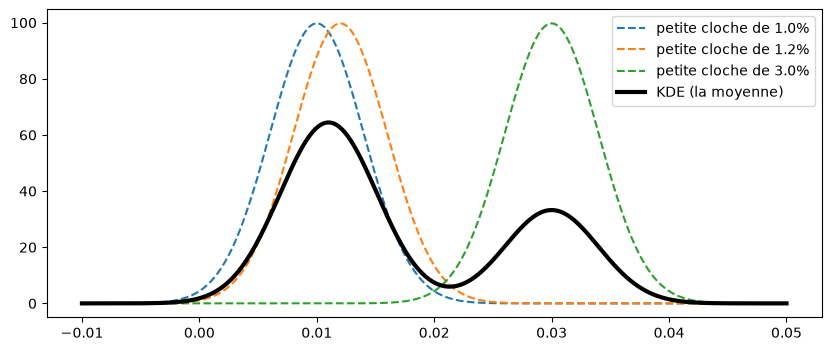

In [60]:
from scipy.stats import norm
pertes = [0.01, 0.012, 0.03]        # 3 pertes : 1 %, 1,2 % et 3 %
h = 0.004                            # la largeur des petites cloches
x = np.linspace(-0.01, 0.05, 500)    # l'axe horizontal

plt.figure(figsize=(10, 4))
somme = 0
for L in pertes:
    cloche = norm.pdf(x, L, h)                                   # la petite cloche de cette perte
    plt.plot(x, cloche, "--", label=f"petite cloche de {L:.1%}")
    somme = somme + cloche                                       # on l'empile

plt.plot(x, somme / len(pertes), color="black", linewidth=3, label="KDE (la moyenne)")
plt.legend()
plt.show()

In [61]:
from src.risk_measures import var_hist, es_hist, var_gaussien, es_gaussien , silverman_bandwidth

print(silverman_bandwidth(losses))

0.0016771493534492208
